**Energy ETF Pairs Trading: Cointegration Analysis & Backtesting**

Facundo 'David' Urquizo

_Statistics and Quantitative Modeling - Data Science_

*FENY–VDE backtest, 2024–2025. Results before trading and borrowing costs.*


[*********************100%***********************]  4 of 4 completed

FENY / IYE: 0.875801 | NOT COINTEGRATED
FENY / VDE: 0.003342 | COINTEGRATED
FENY / XLE: 0.191816 | NOT COINTEGRATED
IYE / VDE: 0.850855 | NOT COINTEGRATED
IYE / XLE: 0.624343 | NOT COINTEGRATED
VDE / XLE: 0.187659 | NOT COINTEGRATED


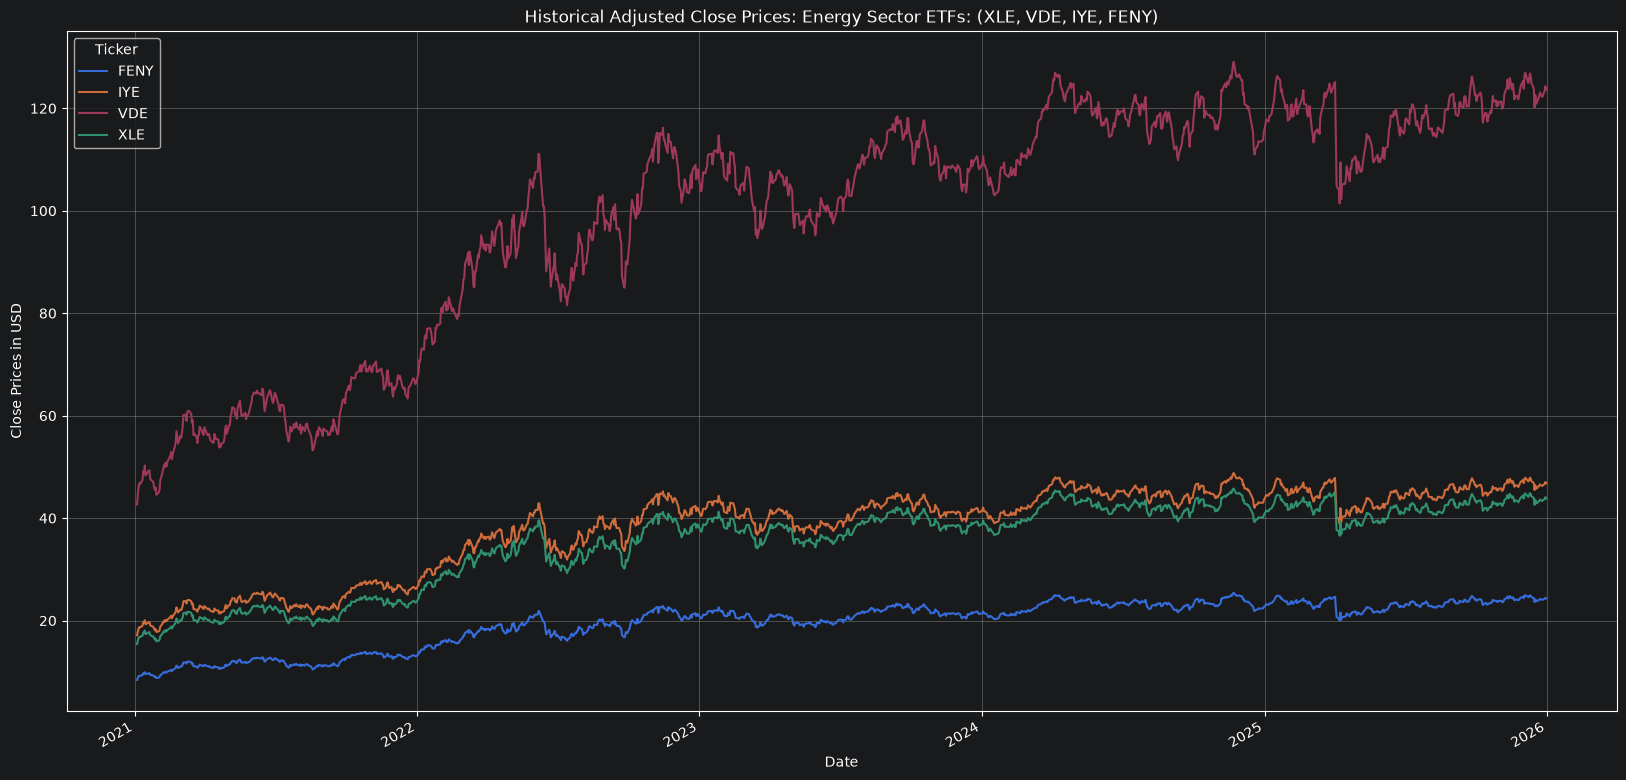

In [58]:
import yfinance as yf
import datetime
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant
from statsmodels.tsa.stattools import coint
import numpy as np
from itertools import combinations

#Definition of classic cointegrated equity pairs for testing
assets = ['XLE', 'VDE', 'IYE', 'FENY']
start_date = datetime.datetime(2021, 1, 1)
end_date = datetime.datetime(2026, 1, 1)

#Retrieve adjusted prices of the selected assets from Yahoo Finance
data = yf.download(assets, start_date, end_date, auto_adjust=True)

#Select the 'Close' column from prices and remove rows with missing values
close_data = data['Close'].copy()
close_data.dropna(inplace=True)

#Use prices from 2024 backwards to calculate p.value and cointegration
training_data = close_data.loc[close_data.index <"2024-01-01"].copy()

#Apply a for loop with combinations to test each pair's training period p-value:
pairs = combinations(training_data.columns,2)

#'For' loop to select the positions, assign the prices and calculate cointegration based on p.value, adjust the 5% significance level for six tests
threshold = 0.05 / 6
for pair in pairs:
    first_asset = pair[0]
    second_asset = pair[1]
    #Extract the price column from the selected ETF:
    first_prices = training_data[first_asset]
    second_prices = training_data[second_asset]
    #Get p value of every combination of pairs possible
    result = coint(first_prices, second_prices, return_results=False)
    p_value = result[1]
    if p_value < threshold: print(f"{first_asset} / {second_asset}: {p_value:.6f} | COINTEGRATED")
    else: print(f"{first_asset} / {second_asset}: {p_value:.6f} | NOT COINTEGRATED")

#Assigned data from 2024 onwards to test the model and evaluate the strategy
testing_data = close_data.loc[close_data.index >= "2024-01-01"].copy()

#Plot historical price series (line graph)
close_data.plot(figsize=(20,10),title='Historical Adjusted Close Prices: Energy Sector ETFs: (XLE, VDE, IYE, FENY)', grid=True, ylabel='Close Prices in USD')
plt.show()

Hedge Ratio (Beta): 0.1967
Mean spread: 0.013016


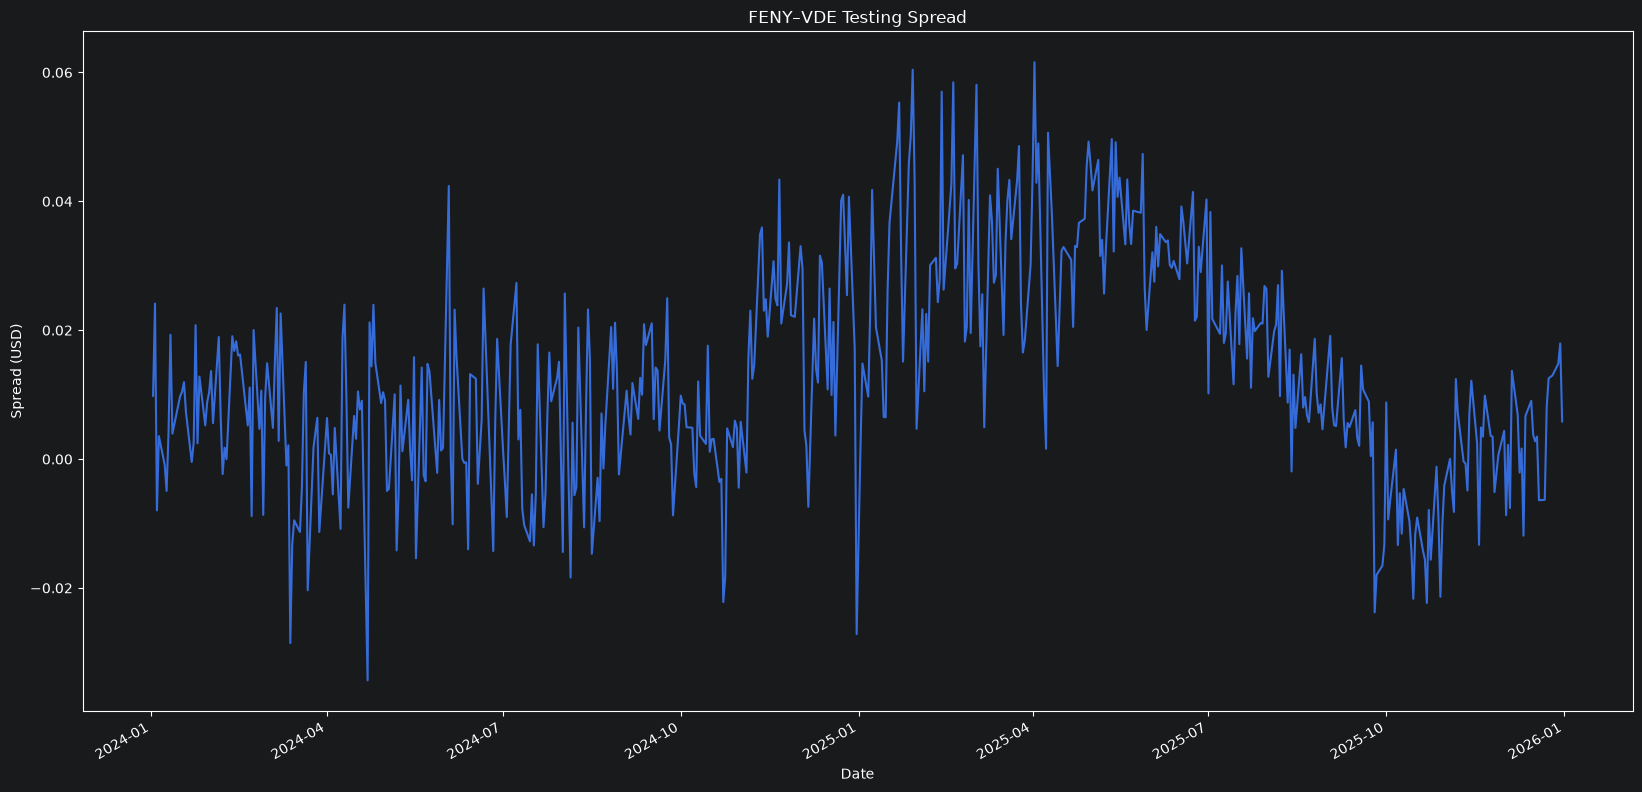

In [59]:
#Selected the data pair with p value less than 0.05:
selected_training_pair = training_data[['FENY', 'VDE']].copy()

#Calculating the hedge ratio (B = Beta x A + Alpha)
#1. Calculate dependent and independent variables: B = FENY; A=VDE
B = selected_training_pair['FENY']
A = selected_training_pair['VDE']
#2 Add constant (Alpha) to A
A_with_constant = add_constant(A)
#3. Fit an OLS Regression algorithm
Ordinary_least_squares = OLS(B, A_with_constant).fit()
#4. Extract the coefficient (Hedge Ratio) and save it in a variable
beta = Ordinary_least_squares.params['VDE']
#5. Construct the spread (it uses constant at its average level)
#Beta scales with price but the intercept adds a fixed dollar amount
##Use testing data instead to calculate spread (the strategy in practice)
testing_pair = testing_data[['FENY', 'VDE']].copy()
series_1 = testing_pair['FENY']
series_2 = testing_pair['VDE']
spread = series_1 - (beta * series_2)
print(f"Hedge Ratio (Beta): {beta:.4f}")
#Display the spread mean
print(f"Mean spread: {spread.mean():.6f}")
#Display the spread plot
spread.plot(figsize=(20, 10), xlabel='Date', ylabel='Spread (USD)', title='FENY–VDE Testing Spread')
plt.show()

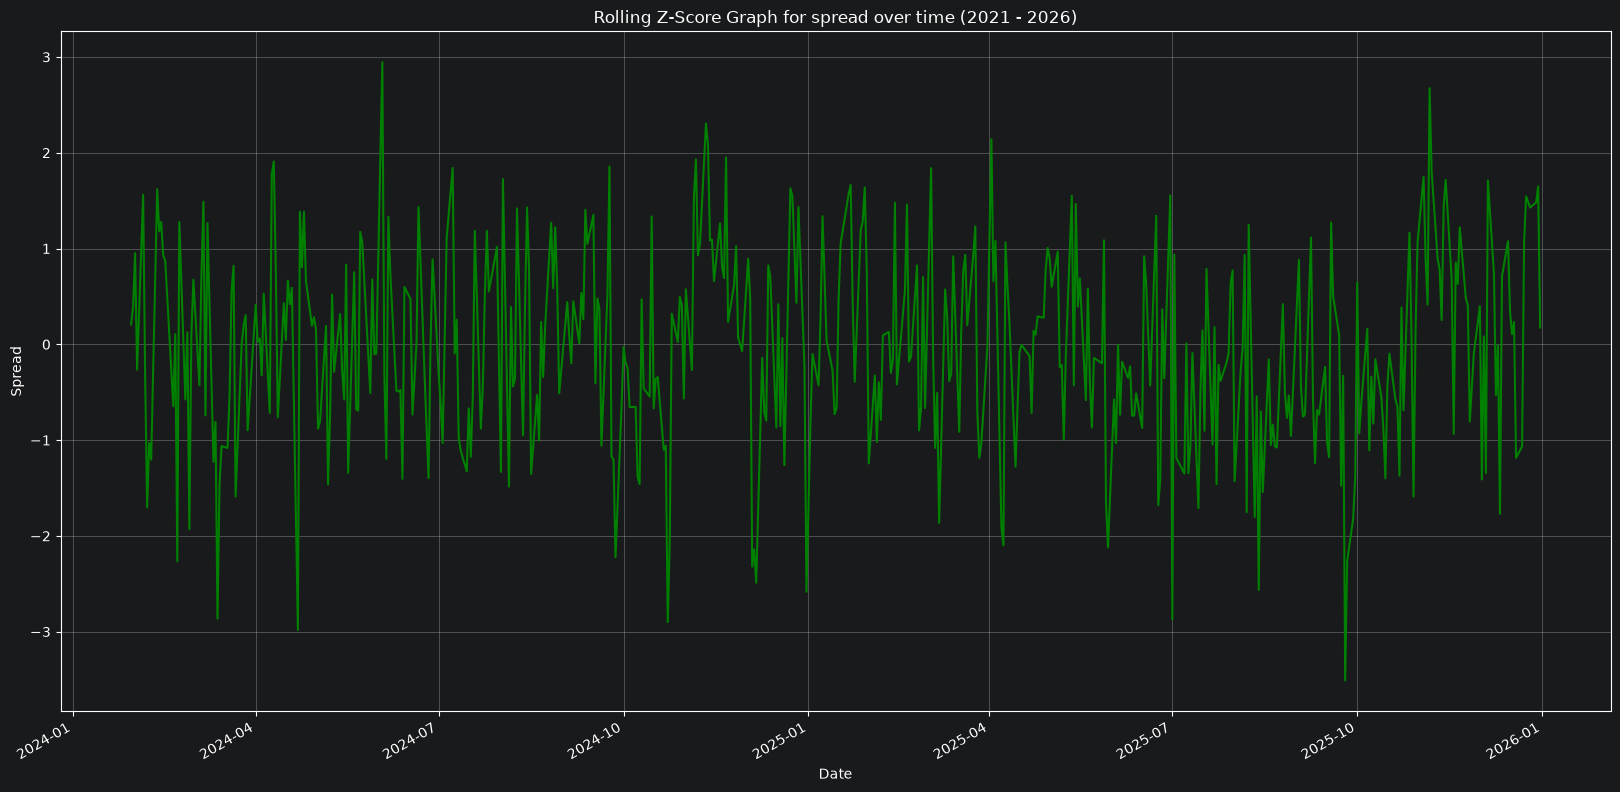

In [60]:
#Rolling Z score (How many standard deviations is the last spread from the mean spread)
rolling_mean = spread.rolling(window=20).mean()
rolling_std =spread.rolling(window=20).std()
rolling_z_score = (spread-rolling_mean)/rolling_std
rolling_z_score_without_NaaNs = rolling_z_score.dropna()
rolling_z_score_without_NaaNs.plot(figsize=(20,10), title='FENY–VDE 20-Day Rolling Z-Score (2024–2025)', color='green', grid=True, ylabel='Z-score', xlabel='Date')
plt.show()

In [62]:
#Discrete Trading Signals: When to choose whether to Buy (-1), Hold (0) or Sell (1)
conditions = [rolling_z_score_without_NaaNs >2.0, rolling_z_score_without_NaaNs <-2.0,(rolling_z_score_without_NaaNs < 0.05) & (rolling_z_score_without_NaaNs > -0.05)]
choices = [-1,1,0]
signals = np.select(conditions, choices,default=np.nan)
#Creating a Series with signals and dates
signals_series = pd.Series(signals, index=rolling_z_score_without_NaaNs.index)
#Defined the positions (holding state) (short, exit, or long) based on signals and used ffill to drag the last value when there's no new value. Pushed  positions forward by one day so that today’s closing signal becomes tomorrow’s actual trading position
positions = signals_series.ffill().shift(1).fillna(0)
print(positions)

Date
2024-01-30    0.0
2024-01-31    0.0
2024-02-01    0.0
2024-02-02    0.0
2024-02-05    0.0
             ... 
2025-12-24    0.0
2025-12-26    0.0
2025-12-29    0.0
2025-12-30    0.0
2025-12-31    0.0
Length: 483, dtype: float64


In [63]:
#Returns Calculation
## Daily dollar profit/loss from long (buy) 1 FENY share and short (sell) beta VDE shares.
spread_profit_and_loss = series_1.diff() - beta * series_2.diff()
# Total absolute value of both positions using yesterday's closing prices
gross_exposure = (series_1.shift(1) + abs(beta) * series_2.shift(1))
## Profit or loss relative to that gross exposure
spread_returns = spread_profit_and_loss / gross_exposure
### Align delayed positions with return dates; use 0 before trading begins
aligned_positions = positions.reindex(spread_returns.index).fillna(0)
strategy_returns = (aligned_positions * spread_returns).dropna()
#Print daily return in percentages
print(strategy_returns.loc[aligned_positions != 0].head(10))


Date
2024-02-23    0.000660
2024-02-26   -0.000353
2024-02-27    0.000136
2024-02-28   -0.000444
2024-02-29    0.000422
2024-03-01    0.000120
2024-03-04   -0.000227
2024-03-05    0.000230
2024-03-06    0.000195
2024-03-07   -0.000468
dtype: float64


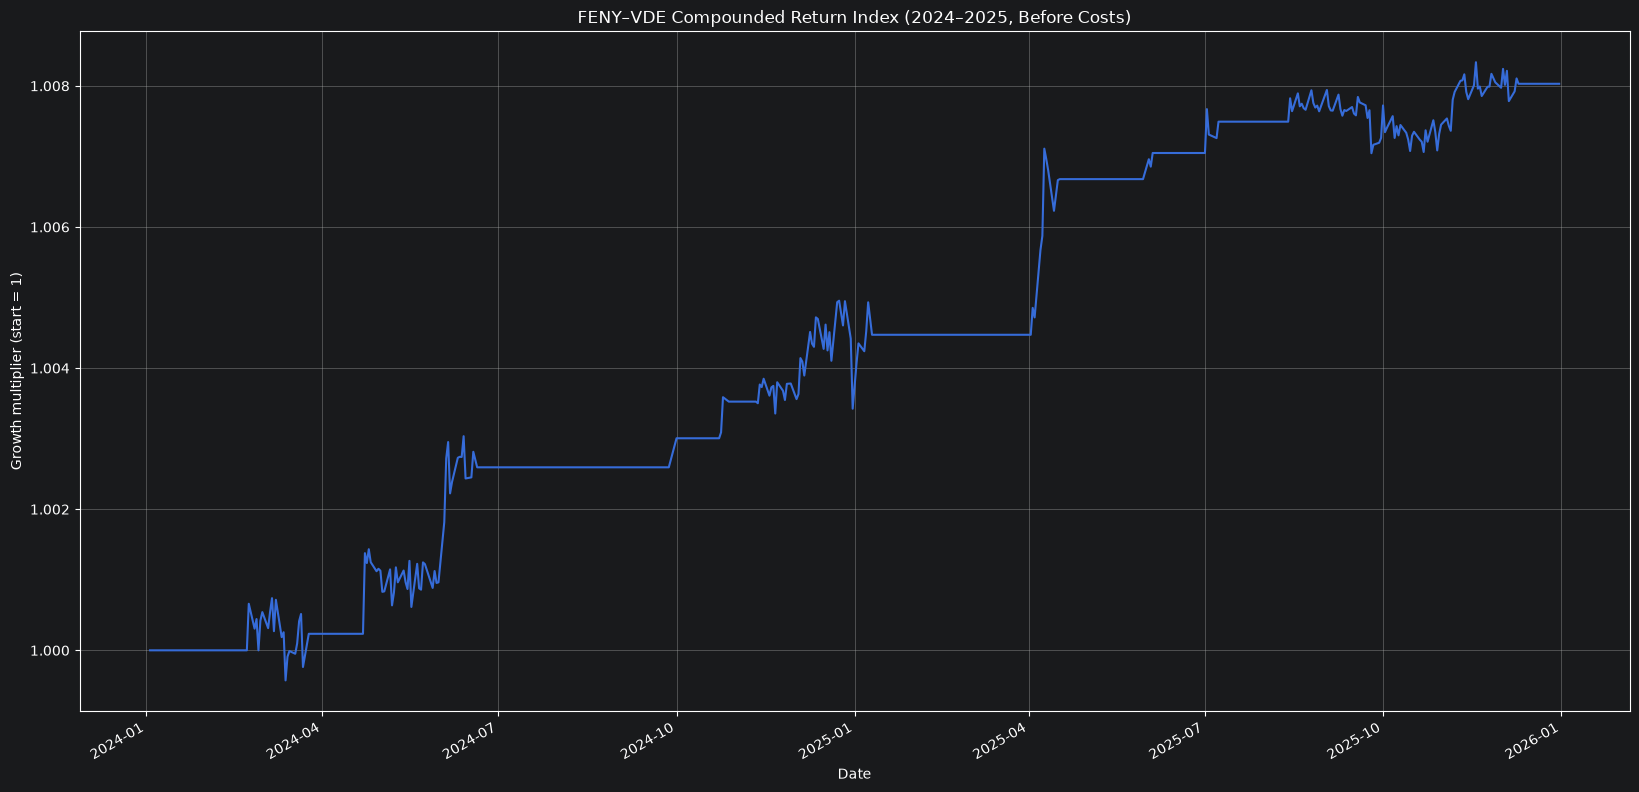

Total return before costs: 0.80%


In [65]:
# Performance evaluation: Calculate the compound growth over time
#Added 1 to multiply by cumprod(), which multiplies percentage changes chronologically
equity_curve = (strategy_returns+1).cumprod()
equity_curve.plot(figsize=(20,10), title='FENY–VDE Compounded Return Index (2024–2025, Before Costs)', grid=True, ylabel='Growth multiplier (start = 1)')
plt.show()
total_return = equity_curve.iloc[-1] - 1
print(f"Total return before costs: {total_return:.2%}")

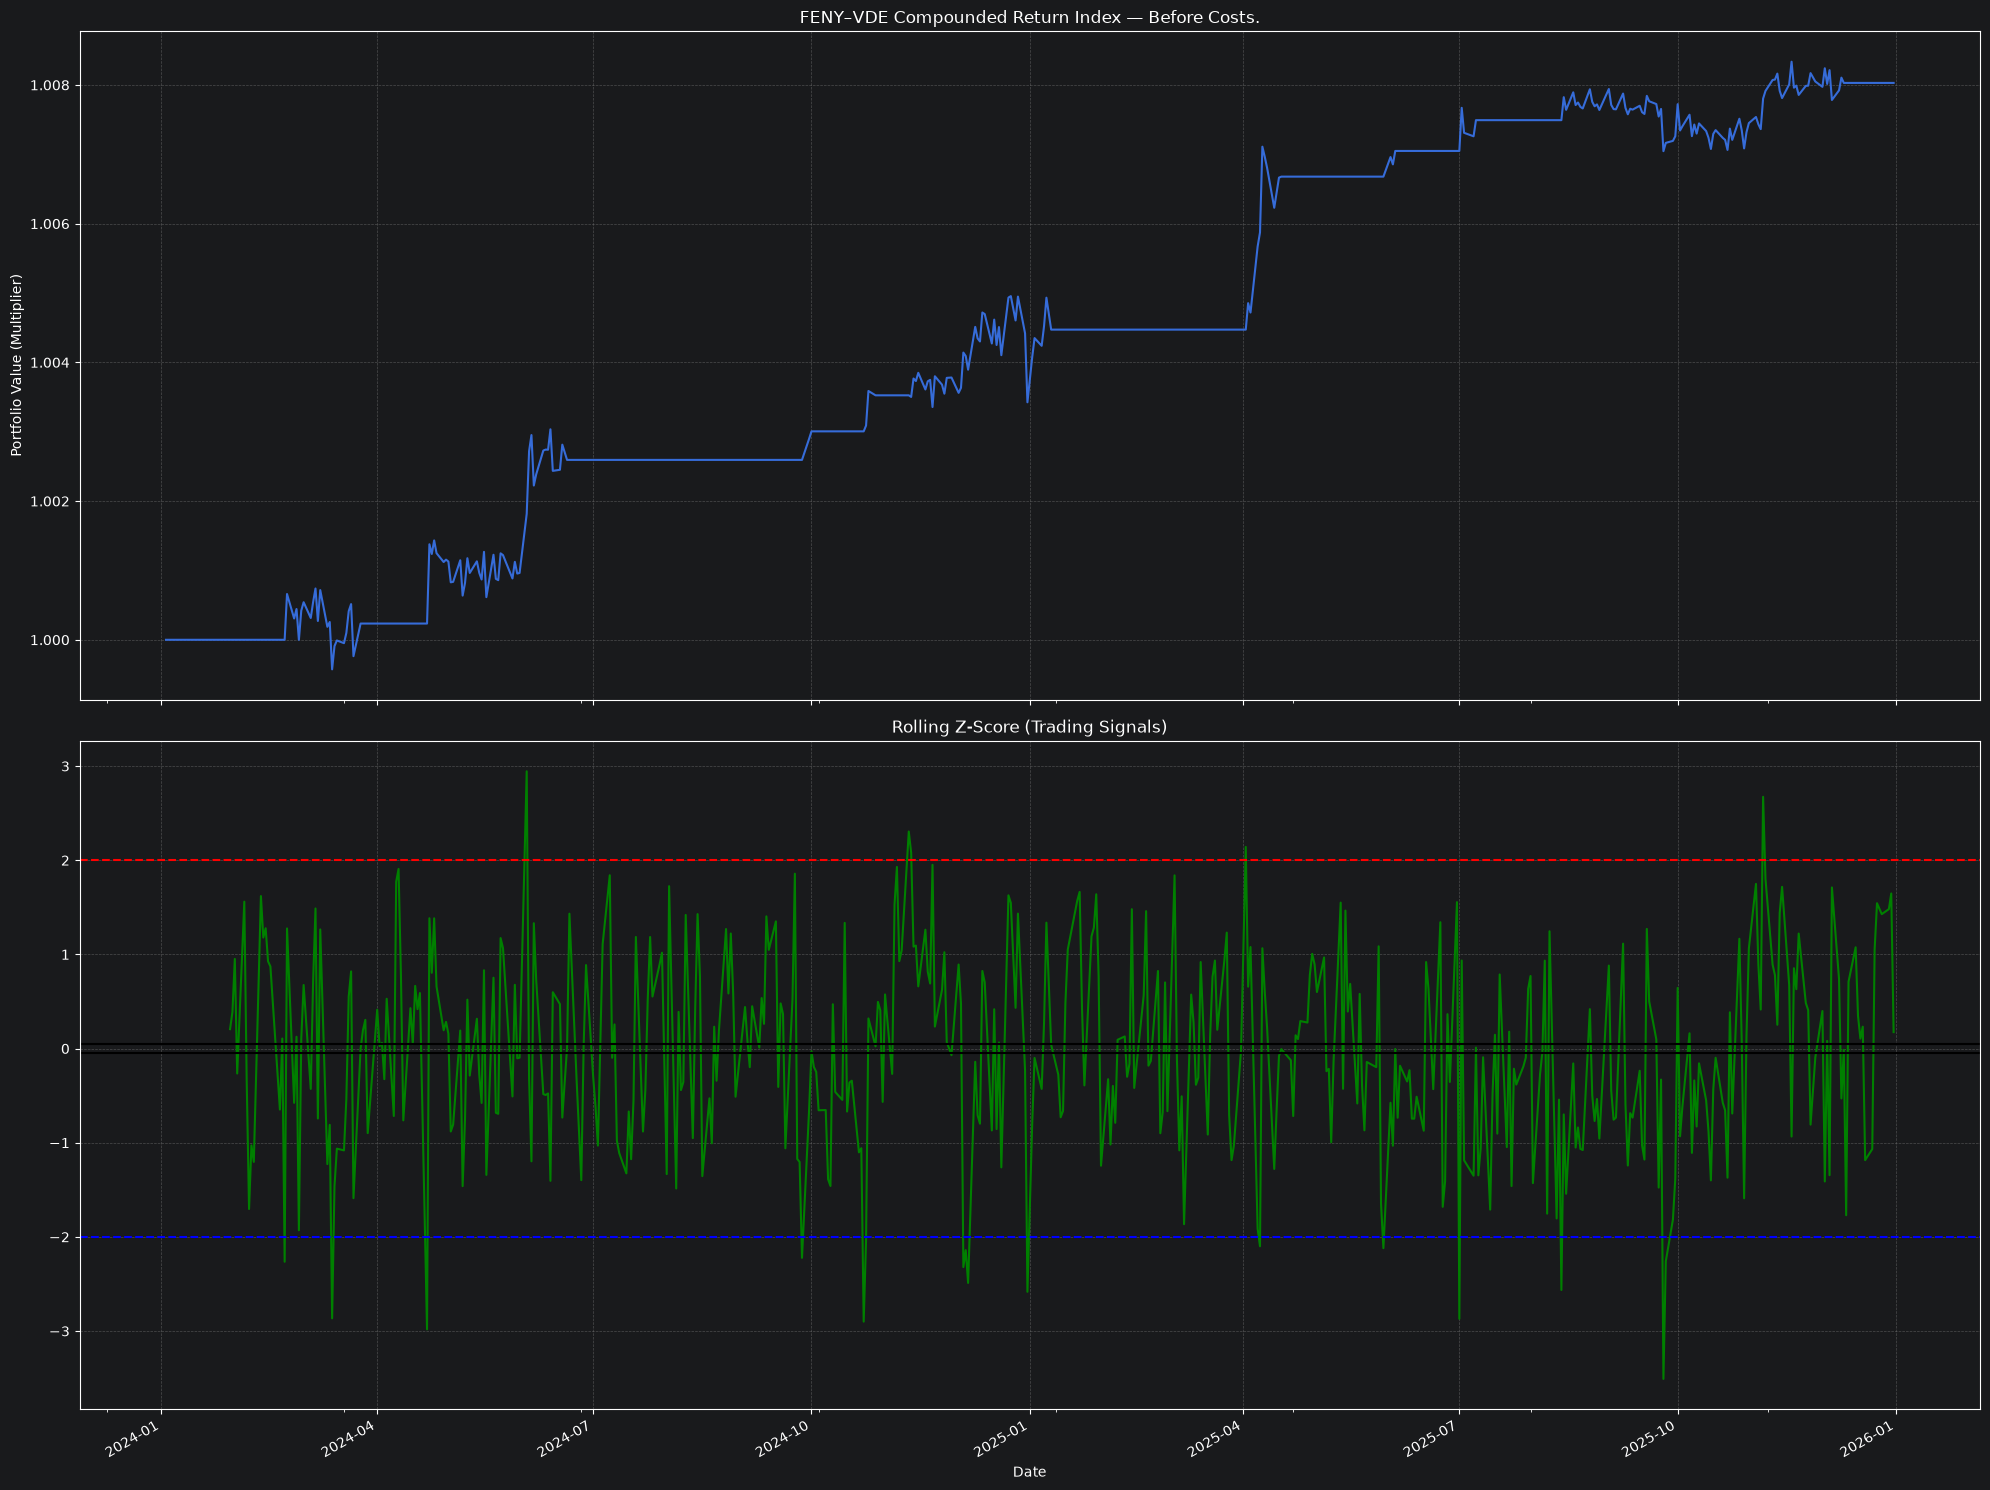

In [46]:
#Visualize rolling_z_score and equity_curve together
#Using subplots to compare the two different variables
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 15), sharex=True)

# Plotting Equity Curve or Portfolio Value Chart
equity_curve.plot(ax=ax1, title='FENY–VDE Compounded Return Index — Before Costs.')
ax1.set_ylabel('Portfolio Value (Multiplier)')
ax1.grid(True, color='grey', linestyle='--', alpha=0.5)

# Plotting Z-Score & Tripwires indicating signals
rolling_z_score_without_NaaNs.plot(ax=ax2, title='Rolling Z-Score (Trading Signals)', color='green')
# Short spread: red (-1); long spread: blue (+1); exit zone: -0.05 to +0.05
ax2.axhline(y=2.0, color='red', linestyle='--')
ax2.axhline(y=-2.0, color='blue', linestyle='--')
ax2.axhline(y=0.05, color='black', linestyle='-')
ax2.axhline(y=-0.05, color='black', linestyle='-')
ax2.grid(True, color='grey', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()